# CMPS 364 — Experimental Results & Visual Analysis

This notebook summarizes **all 18 training runs** across both datasets (**13 KU Leuven FD-I** gesture models + **5 Clemson All-day** meal-episode models), plus **`int8` smartwatch quantization (Q6)** and the **Clemson meal failure breakdown (Q7)**.

Every chart is also exported at **300 DPI** to `results/figures/` so it can be dropped straight into the **A1 Poster**.

### Headline Results (Unseen Test Splits)
| Task / Question | Winning Model | Key Unseen Test Metrics |
|---|---|---|
| **Q1 & Q2** (Bites, Sips, Count & Speed) | `fd1_cnn_gru_cw_none` | Bite Event F1 **0.817**, Drink Event F1 **0.834**, **0** eat↔drink confusion, Bite MAE **22.0**, Speed MAE **0.86 bites/min** |
| **Q4** (Fast Offline Watch Model) | `fd1_cnn_cw_none` | Bite Event F1 **0.776**, Drink Event F1 **0.837**, **5.7 ms/min** (18× faster than GRU) |
| **Live Demo** (0.0 s Look-Ahead) | `fd1_cnn_causal_cw_none` | Bite Event F1 **0.751**, Drink Event F1 **0.787**, **0.0 s** delay, **5.7 ms/min** |
| **Q6** (Watch `int8` Compression) | Static FX `int8` | CNN & Causal CNN shrink **3.2×** (`0.87 → 0.27 MB`) with **zero accuracy loss** (`0.780` & `0.759` Test Bite F1) |
| **Q3 & Q9** (Full-Day Meals & Daily Totals) | `clemson_cnn_pw_none` | Episode F1 **0.694** (`71.5%` meals found, `1.94` FP/day), Start/End err **4.1 / 6.5 min**, Meals/Day MAE **1.02** |
| **Q7** (Clemson Failure Modes) | `meal_breakdown_test.json` | Short meals `<5 min` drop to **45.5%** (vs. **85.7%** for `30+ min`); Left-handed users drop to **33.3%** (vs. **74.3%** Right-handed) |


In [4]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Locate repository root whether launched from repo root or a subfolder
ROOT = Path.cwd()
while not (ROOT / "results" / "runs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

RUNS_DIR = ROOT / "results" / "runs"
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Clean, poster-friendly styling
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def save_fig(fig, filename):
    out = FIG_DIR / filename
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"Saved: {out.relative_to(ROOT)}")

fd1_runs = {}
clemson_runs = {}

for run_dir in sorted(RUNS_DIR.iterdir()):
    metrics_path = run_dir / "metrics.json"
    if not metrics_path.exists():
        continue
    metrics = load_json(metrics_path)
    config = load_json(run_dir / "config.json") if (run_dir / "config.json").exists() else {}
    history = load_json(run_dir / "history.json") if (run_dir / "history.json").exists() else []
    quant = load_json(run_dir / "quantization.json") if (run_dir / "quantization.json").exists() else None
    entry = {"dir": run_dir, "metrics": metrics, "config": config, "history": history, "quant": quant}

    if "bite_count" in metrics.get("validation", {}):
        fd1_runs[run_dir.name] = entry
    elif "episodes" in metrics.get("validation", {}):
        clemson_runs[run_dir.name] = entry

print(f"Loaded {len(fd1_runs)} KU Leuven FD-I runs and {len(clemson_runs)} Clemson All-day runs.")
print("KU Leuven:", list(fd1_runs.keys()))
print("Clemson:  ", list(clemson_runs.keys()))


Loaded 13 KU Leuven FD-I runs and 5 Clemson All-day runs.
KU Leuven: ['fd1_cnn', 'fd1_cnn_causal', 'fd1_cnn_causal_cw_none', 'fd1_cnn_cw_none', 'fd1_cnn_gru', 'fd1_cnn_gru_ch96', 'fd1_cnn_gru_cw_none', 'fd1_cnn_gru_lr5e4', 'fd1_cnn_gru_reg', 'fd1_cnn_reg', 'fd1_transformer', 'fd1_transformer_cw_none', 'fd1_transformer_lr3e4']
Clemson:   ['clemson_cnn_base', 'clemson_cnn_pw2_lr5e4', 'clemson_cnn_pw_none', 'clemson_cnn_pw_none_reg', 'clemson_cnn_reg']


---
## 1. KU Leuven FD-I — Class-Weight Ablation (`sqrt` vs. `none`)

**Key Finding:** Training with default `sqrt` inverse-frequency weights (`[1.0, 10.6, 16.9]`) pushed predicted eating probabilities upward so default `argmax` triggered excessive false-positive bites. Switching to **unweighted cross-entropy (`--class-weight none`)** improved **every single architecture** by **+0.05 to +0.30 Bite Event F1** and slashed Bite Count MAE by up to **4×** (rescuing our 0-delay Causal CNN for the live demo!).


Saved: results\figures\01_fd1_class_weight_ablation.png


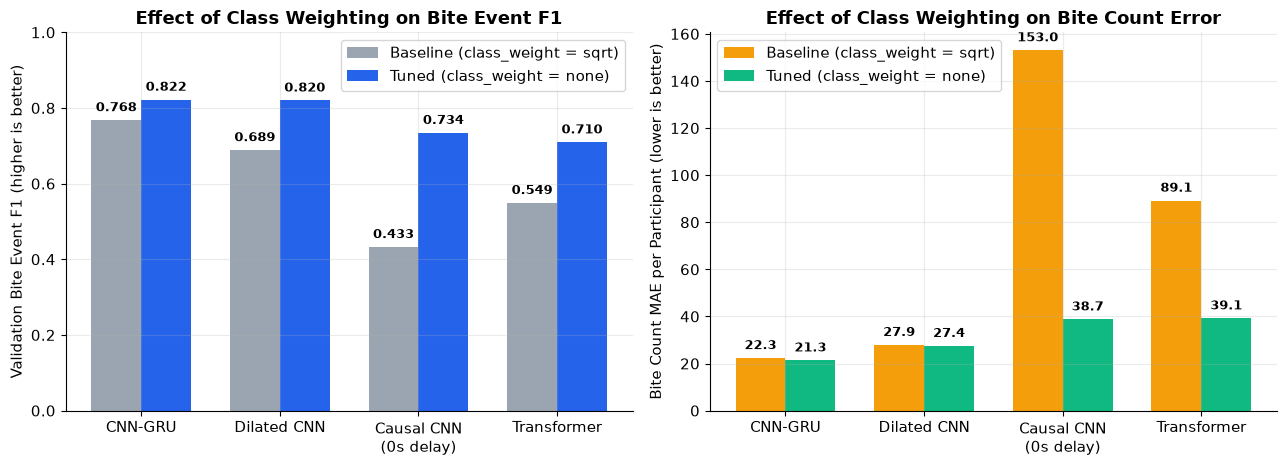

In [5]:
pairs = [
    ("CNN-GRU", "fd1_cnn_gru", "fd1_cnn_gru_cw_none"),
    ("Dilated CNN", "fd1_cnn", "fd1_cnn_cw_none"),
    ("Causal CNN\n(0s delay)", "fd1_cnn_causal", "fd1_cnn_causal_cw_none"),
    ("Transformer", "fd1_transformer", "fd1_transformer_cw_none"),
]

labels = [p[0] for p in pairs]
x = np.arange(len(labels))
width = 0.36

sqrt_f1 = [fd1_runs[p[1]]["metrics"]["validation"]["events"]["eating"]["f1"] for p in pairs]
none_f1 = [fd1_runs[p[2]]["metrics"]["validation"]["events"]["eating"]["f1"] for p in pairs]
sqrt_mae = [fd1_runs[p[1]]["metrics"]["validation"]["bite_count"]["per_participant_error"]["mae"] for p in pairs]
none_mae = [fd1_runs[p[2]]["metrics"]["validation"]["bite_count"]["per_participant_error"]["mae"] for p in pairs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

b1 = ax1.bar(x - width/2, sqrt_f1, width, label="Baseline (class_weight = sqrt)", color="#9aa5b1")
b2 = ax1.bar(x + width/2, none_f1, width, label="Tuned (class_weight = none)", color="#2563eb")
ax1.set_xticks(x); ax1.set_xticklabels(labels)
ax1.set_ylim(0, 1.0)
ax1.set_ylabel("Validation Bite Event F1 (higher is better)")
ax1.set_title("Effect of Class Weighting on Bite Event F1")
ax1.legend()
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

b3 = ax2.bar(x - width/2, sqrt_mae, width, label="Baseline (class_weight = sqrt)", color="#f59e0b")
b4 = ax2.bar(x + width/2, none_mae, width, label="Tuned (class_weight = none)", color="#10b981")
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel("Bite Count MAE per Participant (lower is better)")
ax2.set_title("Effect of Class Weighting on Bite Count Error")
ax2.legend()
for bars in (b3, b4):
    for bar in bars:
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h + 2.5, f"{h:.1f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

plt.tight_layout()
save_fig(fig, "01_fd1_class_weight_ablation.png")
plt.show()


---
## 2. KU Leuven FD-I — Training Curves Across All 13 Runs

Solid bold lines highlight the **4 tuned winning models** (`--class-weight none`); faint dashed lines show the earlier baseline & hyperparameter exploration runs.


Saved: results\figures\02_fd1_training_curves.png


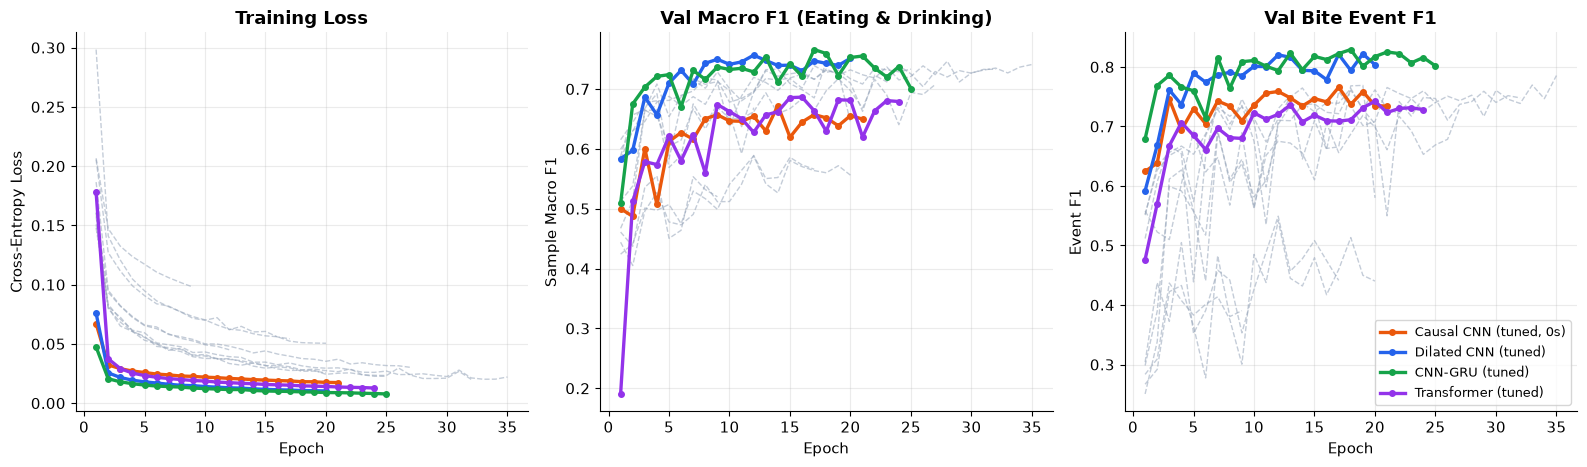

In [6]:
winners_style = {
    "fd1_cnn_gru_cw_none": ("CNN-GRU (tuned)", "#16a34a"),
    "fd1_cnn_cw_none": ("Dilated CNN (tuned)", "#2563eb"),
    "fd1_cnn_causal_cw_none": ("Causal CNN (tuned, 0s)", "#ea580c"),
    "fd1_transformer_cw_none": ("Transformer (tuned)", "#9333ea"),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for name, entry in fd1_runs.items():
    hist = entry["history"]
    if not hist:
        continue
    epochs = [h["epoch"] for h in hist]
    if name in winners_style:
        label, color = winners_style[name]
        kw = dict(color=color, linewidth=2.4, marker="o", markersize=4, label=label, zorder=4)
    else:
        kw = dict(color="#94a3b8", linewidth=1.0, linestyle="--", alpha=0.55, zorder=2)

    axes[0].plot(epochs, [h["train_loss"] for h in hist], **kw)
    axes[1].plot(epochs, [h["val_macro_f1"] for h in hist], **kw)
    axes[2].plot(epochs, [h["val_bite_f1"] for h in hist], **kw)

axes[0].set_title("Training Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-Entropy Loss")
axes[1].set_title("Val Macro F1 (Eating & Drinking)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Sample Macro F1")
axes[2].set_title("Val Bite Event F1"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Event F1")
axes[2].legend(loc="lower right", fontsize=9, frameon=True)

plt.tight_layout()
save_fig(fig, "02_fd1_training_curves.png")
plt.show()


---
## 3. Q4 & Q6 — Architecture Comparison, Speed Trade-Off & `int8` Watch Compression

- **Accuracy Winner:** `CNN-GRU` (**0.817** Test Bite F1, **22.0** Bite MAE)
- **Efficiency Sweet Spot:** `Dilated CNN` (**0.776** Test Bite F1, **5.7 ms/min** — **18× faster** than CNN-GRU!)
- **Live Demo (0 s delay):** `Causal CNN` (**0.751** Test Bite F1, **5.7 ms/min**)
- **Watch Feasibility (`int8`):** Static FX quantization shrinks CNN & Causal CNN **3.2× down to 273 KB** with **zero accuracy loss** (even slight improvement on test!).


Saved: results\figures\03_fd1_q4_q6_tradeoff_int8.png


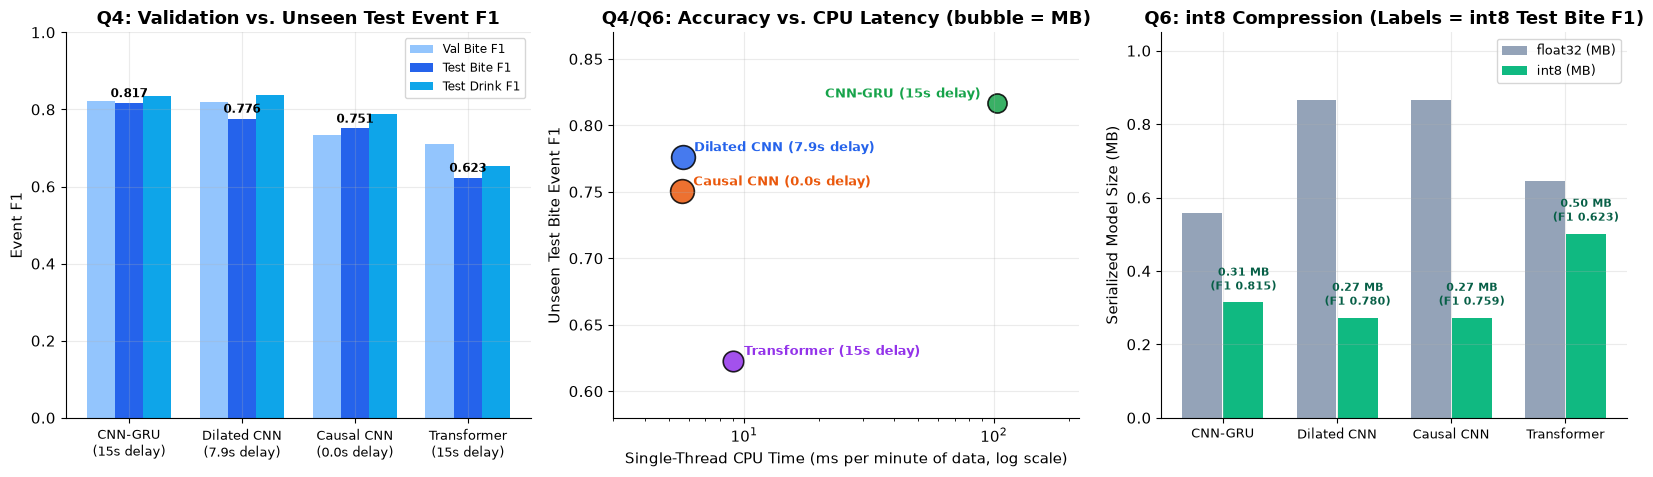

In [7]:
winner_order = [
    ("CNN-GRU\n(15s delay)", "fd1_cnn_gru_cw_none", "#16a34a"),
    ("Dilated CNN\n(7.9s delay)", "fd1_cnn_cw_none", "#2563eb"),
    ("Causal CNN\n(0.0s delay)", "fd1_cnn_causal_cw_none", "#ea580c"),
    ("Transformer\n(15s delay)", "fd1_transformer_cw_none", "#9333ea"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.9))

# Panel A: Val vs Test Bite & Drink Event F1
x = np.arange(len(winner_order))
w = 0.25
val_bite = [fd1_runs[k]["metrics"]["validation"]["events"]["eating"]["f1"] for _, k, _ in winner_order]
test_bite = [fd1_runs[k]["metrics"]["test"]["events"]["eating"]["f1"] for _, k, _ in winner_order]
test_drink = [fd1_runs[k]["metrics"]["test"]["events"]["drinking"]["f1"] for _, k, _ in winner_order]

axes[0].bar(x - w, val_bite, w, label="Val Bite F1", color="#93c5fd")
axes[0].bar(x, test_bite, w, label="Test Bite F1", color="#2563eb")
axes[0].bar(x + w, test_drink, w, label="Test Drink F1", color="#0ea5e9")
axes[0].set_xticks(x); axes[0].set_xticklabels([lbl for lbl, _, _ in winner_order], fontsize=9.5)
axes[0].set_ylim(0, 1.0); axes[0].set_ylabel("Event F1")
axes[0].set_title("Q4: Validation vs. Unseen Test Event F1")
axes[0].legend(fontsize=8.5)
for i, v in enumerate(test_bite):
    axes[0].text(i, v + 0.015, f"{v:.3f}", ha="center", fontsize=8.5, fontweight="bold")

# Panel B: Speed vs Test Accuracy trade-off
for lbl, key, color in winner_order:
    m = fd1_runs[key]["metrics"]
    ms = m["cpu_ms_per_minute_single_thread"]
    f1 = m["test"]["events"]["eating"]["f1"]
    mb = m["size_mb_float32"]
    axes[1].scatter(ms, f1, s=mb * 350, color=color, alpha=0.85, edgecolors="black", linewidth=1.2)
    dx = -12 if ms > 50 else 8
    ha = "right" if ms > 50 else "left"
    axes[1].annotate(lbl.replace("\n", " "), (ms, f1), xytext=(dx, 4), textcoords="offset points",
                     ha=ha, fontsize=9, fontweight="bold", color=color)

axes[1].set_xscale("log")
axes[1].set_xlim(3, 220); axes[1].set_ylim(0.58, 0.87)
axes[1].set_xlabel("Single-Thread CPU Time (ms per minute of data, log scale)")
axes[1].set_ylabel("Unseen Test Bite Event F1")
axes[1].set_title("Q4/Q6: Accuracy vs. CPU Latency (bubble = MB)")

# Panel C: float32 vs int8 model size + Test Bite F1 annotations
f32_mb = [fd1_runs[k]["quant"]["float32"]["size_mb"] for _, k, _ in winner_order]
i8_mb = [fd1_runs[k]["quant"]["int8"]["size_mb"] for _, k, _ in winner_order]
i8_f1 = [fd1_runs[k]["quant"]["int8"]["test"]["bite_event_f1"] for _, k, _ in winner_order]

b_f32 = axes[2].bar(x - 0.18, f32_mb, 0.35, label="float32 (MB)", color="#94a3b8")
b_i8 = axes[2].bar(x + 0.18, i8_mb, 0.35, label="int8 (MB)", color="#10b981")
axes[2].set_xticks(x); axes[2].set_xticklabels([lbl.split("\n")[0] for lbl, _, _ in winner_order], fontsize=9.5)
axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("Serialized Model Size (MB)")
axes[2].set_title("Q6: int8 Compression (Labels = int8 Test Bite F1)")
axes[2].legend(fontsize=9)
for bar, f1_val in zip(b_i8, i8_f1):
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 0.025, f"{h:.2f} MB\n(F1 {f1_val:.3f})",
                 ha="center", va="bottom", fontsize=8, fontweight="bold", color="#065f46")

plt.tight_layout()
save_fig(fig, "03_fd1_q4_q6_tradeoff_int8.png")
plt.show()


---
## 4. Q1 & Q2 — Confusion Matrix, Bite Counting & Eating Speed (`fd1_cnn_gru_cw_none`)

Notice on the unseen test set there is **0 eating-predicted-as-drinking** and **0 drinking-predicted-as-eating**! Both bite count and eating speed track the true diagonal closely across unseen participants.


Saved: results\figures\04_fd1_q1_q2_confusion_bites_speed.png


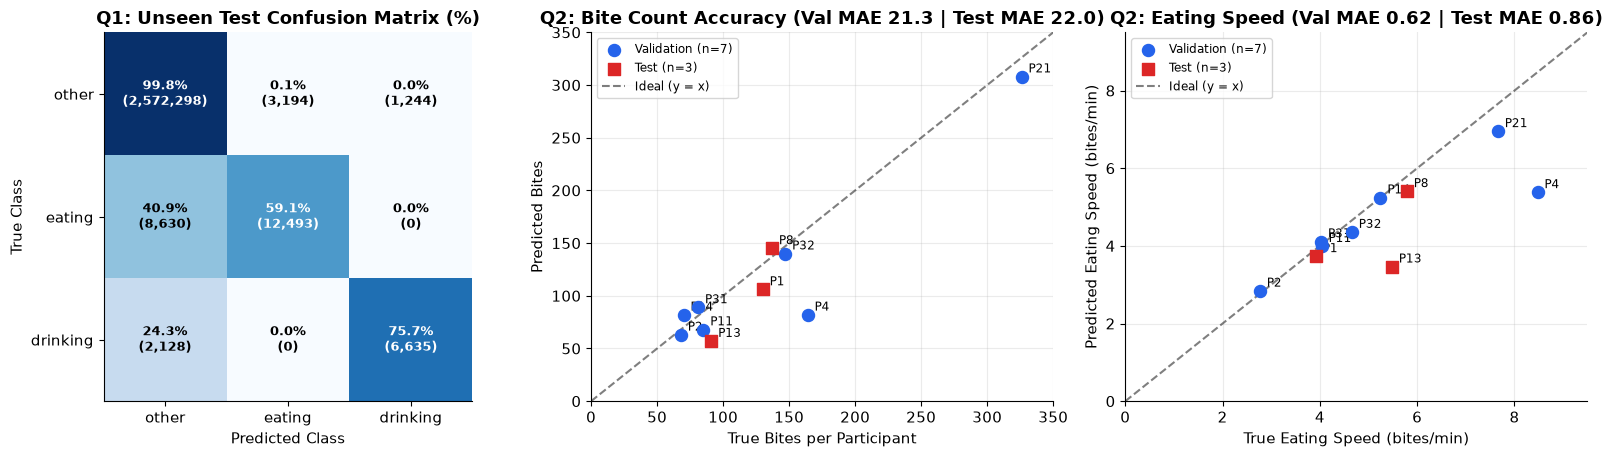

In [8]:
best_fd1 = fd1_runs["fd1_cnn_gru_cw_none"]["metrics"]
cm = np.array(best_fd1["test"]["sample"]["confusion_matrix_rows_true_cols_pred"], dtype=float)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
class_names = best_fd1["test"]["sample"]["class_names"]

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))

# Panel A: Row-normalized confusion matrix on unseen TEST
im = axes[0].imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
axes[0].grid(False)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(class_names)
axes[0].set_yticks(range(3)); axes[0].set_yticklabels(class_names)
axes[0].set_xlabel("Predicted Class"); axes[0].set_ylabel("True Class")
axes[0].set_title("Q1: Unseen Test Confusion Matrix (%)")
for r in range(3):
    for c in range(3):
        val = cm_pct[r, c]
        cnt = int(cm[r, c])
        axes[0].text(c, r, f"{val:.1f}%\n({cnt:,})", ha="center", va="center",
                     color="white" if val > 55 else "black", fontsize=9, fontweight="bold")

# Panel B: True vs Predicted Bites per participant (Val + Test)
for split, color, marker in [("validation", "#2563eb", "o"), ("test", "#dc2626", "s")]:
    pts = best_fd1[split]["bite_count"]["per_participant"]
    xs = [p["true_bites"] for p in pts]
    ys = [p["predicted_bites"] for p in pts]
    axes[1].scatter(xs, ys, s=75, color=color, marker=marker, label=f"{split.title()} (n={len(pts)})", zorder=4)
    for p in pts:
        axes[1].annotate(f"P{p['participant_id']}", (p["true_bites"], p["predicted_bites"]),
                         xytext=(5, 3), textcoords="offset points", fontsize=8.5)

lim = 350
axes[1].plot([0, lim], [0, lim], "k--", alpha=0.5, label="Ideal (y = x)")
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim)
axes[1].set_xlabel("True Bites per Participant"); axes[1].set_ylabel("Predicted Bites")
axes[1].set_title("Q2: Bite Count Accuracy (Val MAE 21.3 | Test MAE 22.0)")
axes[1].legend(fontsize=8.5)

# Panel C: True vs Predicted Eating Speed (bites/min)
for split, color, marker in [("validation", "#2563eb", "o"), ("test", "#dc2626", "s")]:
    pts = best_fd1[split]["eating_speed"]["per_participant"]
    xs = [p["true"]["bites_per_minute"] for p in pts if p["true"]["bites_per_minute"] and p["predicted"]["bites_per_minute"]]
    ys = [p["predicted"]["bites_per_minute"] for p in pts if p["true"]["bites_per_minute"] and p["predicted"]["bites_per_minute"]]
    pids = [p["participant_id"] for p in pts if p["true"]["bites_per_minute"] and p["predicted"]["bites_per_minute"]]
    axes[2].scatter(xs, ys, s=75, color=color, marker=marker, label=f"{split.title()} (n={len(xs)})", zorder=4)
    for pid, xv, yv in zip(pids, xs, ys):
        axes[2].annotate(f"P{pid}", (xv, yv), xytext=(5, 3), textcoords="offset points", fontsize=8.5)

axes[2].plot([0, 9.5], [0, 9.5], "k--", alpha=0.5, label="Ideal (y = x)")
axes[2].set_xlim(0, 9.5); axes[2].set_ylim(0, 9.5)
axes[2].set_xlabel("True Eating Speed (bites/min)"); axes[2].set_ylabel("Predicted Eating Speed (bites/min)")
axes[2].set_title("Q2: Eating Speed (Val MAE 0.62 | Test MAE 0.86)")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
save_fig(fig, "04_fd1_q1_q2_confusion_bites_speed.png")
plt.show()


---
## 5. Clemson All-day — Model Tuning, Meal Detection & Daily Totals (Q3 & Q9)

Across 5 runs (`248` train / `53` val / `53` test full-day recordings, `4,704` total hours), **`clemson_cnn_pw_none`** achieved the best balance of **Episode F1 (`0.761` val / `0.694` test)**, **low false alarms (`1.22` val / `1.94` test per day)**, **Time F1 (`0.586` val / `0.551` test)**, and **daily eating-time accuracy** (whereas `clemson_cnn_reg` had slightly higher val Ep F1 `0.780` only by stretching meal end times to `11.1 min` error and doubling predicted daily eating time to `78.8 min`).


Saved: results\figures\05_clemson_q3_q9_comparison.png


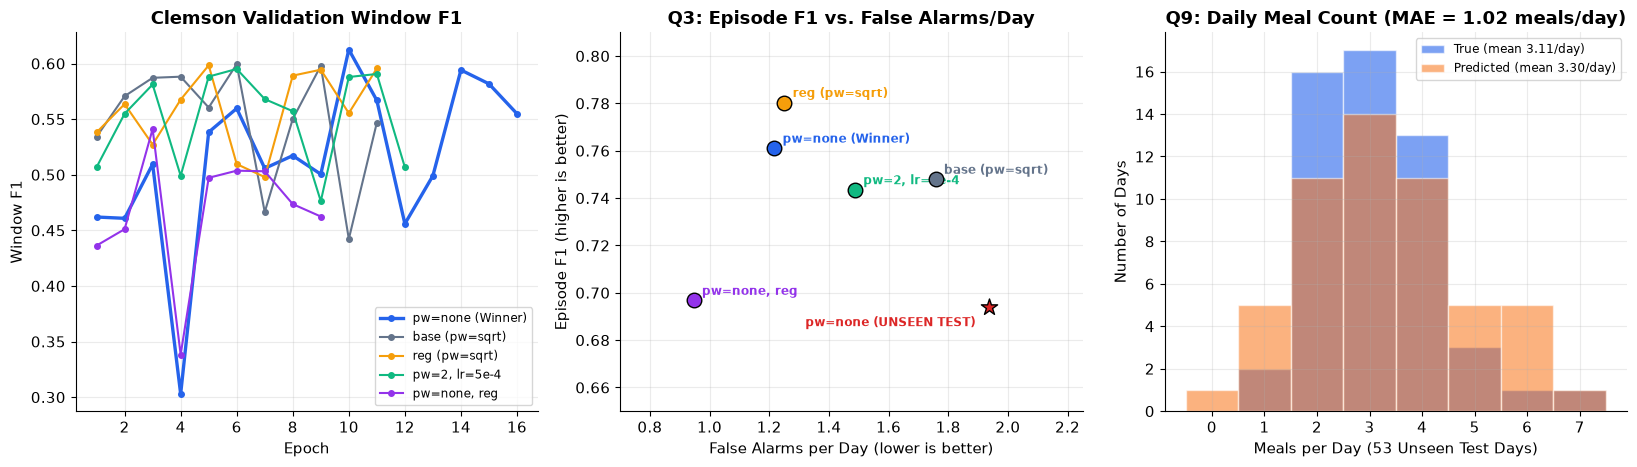

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Validation Window F1 training curves across all 5 Clemson runs
clemson_colors = {
    "clemson_cnn_pw_none": ("pw=none (Winner)", "#2563eb", 2.4),
    "clemson_cnn_base": ("base (pw=sqrt)", "#64748b", 1.5),
    "clemson_cnn_reg": ("reg (pw=sqrt)", "#f59e0b", 1.5),
    "clemson_cnn_pw2_lr5e4": ("pw=2, lr=5e-4", "#10b981", 1.5),
    "clemson_cnn_pw_none_reg": ("pw=none, reg", "#9333ea", 1.5),
}
for name, (lbl, color, lw) in clemson_colors.items():
    if name not in clemson_runs:
        continue
    hist = clemson_runs[name]["history"]
    axes[0].plot([h["epoch"] for h in hist], [h["val_window_f1"] for h in hist],
                 marker="o", markersize=4, color=color, linewidth=lw, label=lbl)
axes[0].set_title("Clemson Validation Window F1")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Window F1")
axes[0].legend(fontsize=8.5)

# Panel B: Episode F1 vs False Alarms/Day (Val runs + Winner Test)
for name, (lbl, color, _) in clemson_colors.items():
    if name not in clemson_runs:
        continue
    v = clemson_runs[name]["metrics"]["validation"]
    fp = v["episodes"]["false_alarms_per_day"]
    ep = v["episodes"]["f1"]
    axes[1].scatter(fp, ep, s=110, color=color, edgecolors="black", zorder=4)
    axes[1].annotate(lbl, (fp, ep), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=color, fontweight="bold")

t_win = clemson_runs["clemson_cnn_pw_none"]["metrics"]["test"]
axes[1].scatter(t_win["episodes"]["false_alarms_per_day"], t_win["episodes"]["f1"],
                s=150, marker="*", color="#dc2626", edgecolors="black", zorder=5, label="Winner on Unseen TEST")
axes[1].annotate("pw=none (UNSEEN TEST)", (t_win["episodes"]["false_alarms_per_day"], t_win["episodes"]["f1"]),
                 xytext=(-10, -14), textcoords="offset points", ha="right", fontsize=8.5, color="#dc2626", fontweight="bold")
axes[1].set_xlabel("False Alarms per Day (lower is better)")
axes[1].set_ylabel("Episode F1 (higher is better)")
axes[1].set_title("Q3: Episode F1 vs. False Alarms/Day")
axes[1].set_xlim(0.7, 2.25); axes[1].set_ylim(0.65, 0.81)

# Panel C: Q9 Daily Meals/Day distribution (True vs Predicted on 53 Unseen Test Days)
recs = t_win["per_recording"]
true_meals = [r["true_meals"] for r in recs]
pred_meals = [r["predicted_meals"] for r in recs]
dt = t_win["daily_totals"]

bins = np.arange(0, max(max(true_meals), max(pred_meals)) + 2) - 0.5
axes[2].hist(true_meals, bins=bins, alpha=0.6, label=f"True (mean {dt['mean_true_meals_per_day']:.2f}/day)", color="#2563eb", edgecolor="white")
axes[2].hist(pred_meals, bins=bins, alpha=0.55, label=f"Predicted (mean {dt['mean_predicted_meals_per_day']:.2f}/day)", color="#f97316", edgecolor="white")
axes[2].set_xlabel("Meals per Day (53 Unseen Test Days)")
axes[2].set_ylabel("Number of Days")
axes[2].set_title(f"Q9: Daily Meal Count (MAE = {dt['meals_per_day_mae']:.2f} meals/day)")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
save_fig(fig, "05_clemson_q3_q9_comparison.png")
plt.show()


---
## 6. Q7 — Clemson Failure Breakdown on Unseen Test Set (`meal_breakdown_test.json`)

Two major real-world failure modes stand out clearly on the **53 unseen test days (165 meals)**:
1. **Brief eating events (`< 5 min` / Snacks):** Detection falls sharply from **85.7%** (`30+ min`) down to **45.5%** (`< 5 min`) due to the 6-minute window + 3-minute stride.
2. **Left-Handed Users:** Detection falls from **74.3%** for Right-handed users (`Right`+`R`, `110/148`) to **33.3%** for Left-handed (`Left`, `4/12`), directly revealing wrist-axis mirroring bias!


Saved: results\figures\06_clemson_q7_failure_breakdown.png


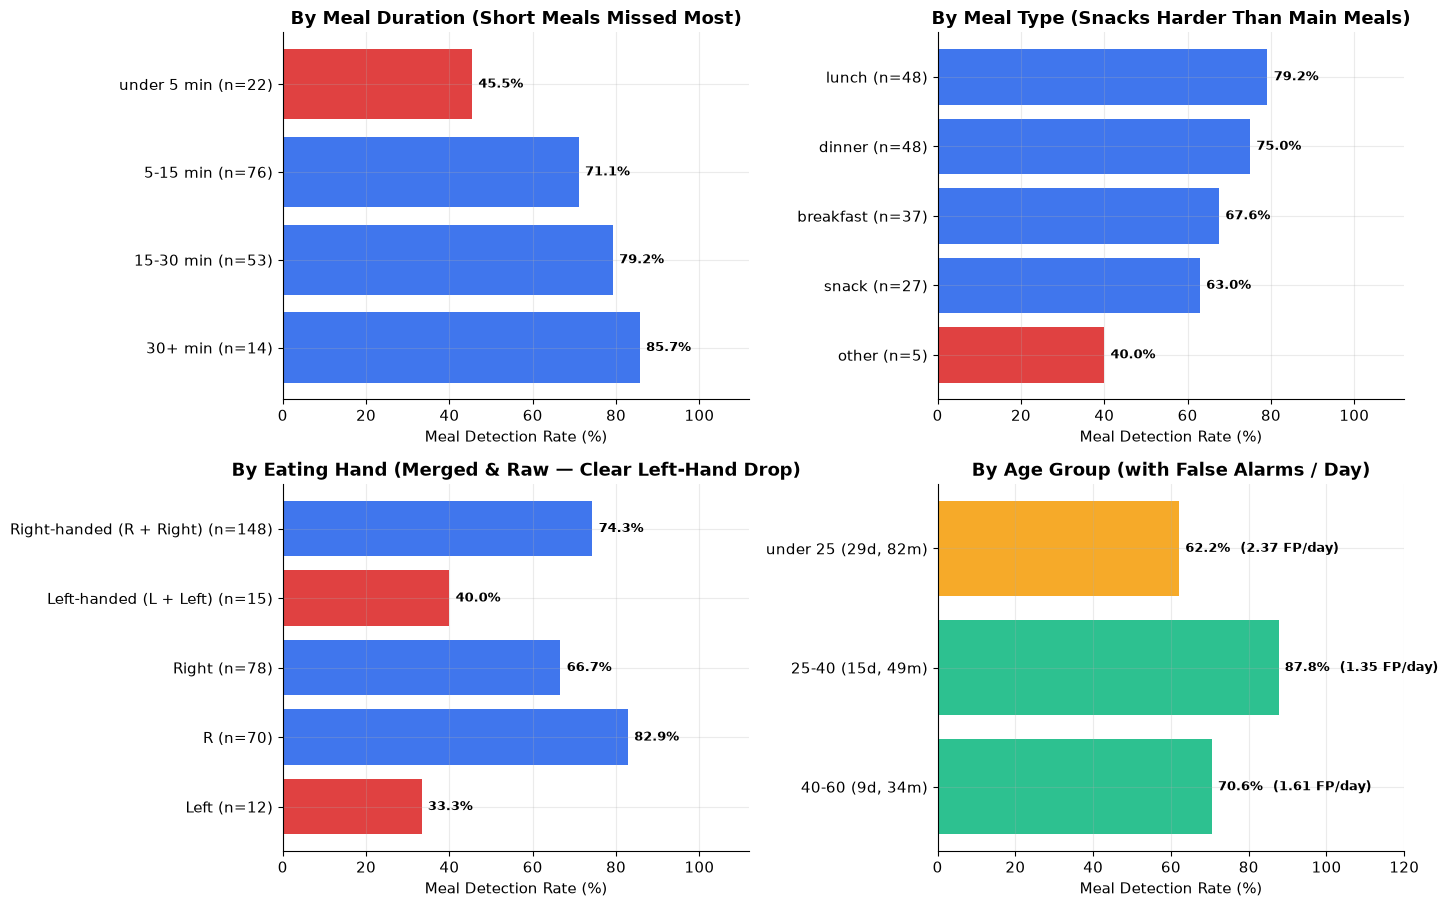

In [10]:
bd = load_json(RUNS_DIR / "clemson_cnn_pw_none" / "meal_breakdown_test.json")

fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.2))

def plot_hbar(ax, rows, title, highlight_low=0.55):
    names = [f"{r['group']} (n={r['events']})" for r in rows]
    rates = [r["detection_rate"] * 100 for r in rows]
    colors = ["#dc2626" if r < highlight_low * 100 else "#2563eb" for r in rates]
    y = np.arange(len(names))
    bars = ax.barh(y, rates, color=colors, alpha=0.88)
    ax.set_yticks(y); ax.set_yticklabels(names)
    ax.invert_yaxis()
    ax.set_xlim(0, 112)
    ax.set_xlabel("Meal Detection Rate (%)")
    ax.set_title(title)
    for bar, r in zip(bars, rates):
        ax.text(r + 1.5, bar.get_y() + bar.get_height()/2, f"{r:.1f}%", va="center", fontsize=9.5, fontweight="bold")

# 1. By Meal Duration (ordered logically)
dur_order = ["under 5 min", "5-15 min", "15-30 min", "30+ min"]
dur_map = {r["group"]: r for r in bd["by_event"]["duration"]}
plot_hbar(axes[0, 0], [dur_map[k] for k in dur_order if k in dur_map], "By Meal Duration (Short Meals Missed Most)")

# 2. By Meal Type
plot_hbar(axes[0, 1], bd["by_event"]["meal_type"], "By Meal Type (Snacks Harder Than Main Meals)")

# 3. By Eating Hand (merge Right/R and Left/L cleanly for clarity)
hand_raw = bd["by_person"]["eating_hand"]
merged = {"Right-handed (R + Right)": [0, 0], "Left-handed (L + Left)": [0, 0]}
for r in hand_raw:
    g = r["group"].lower()
    if g in ("right", "r"):
        merged["Right-handed (R + Right)"][0] += round(r["detection_rate"] * r["meals"])
        merged["Right-handed (R + Right)"][1] += r["meals"]
    elif g in ("left", "l"):
        merged["Left-handed (L + Left)"][0] += round(r["detection_rate"] * r["meals"])
        merged["Left-handed (L + Left)"][1] += r["meals"]

hand_rows = [
    {"group": k, "events": tot, "detection_rate": det / tot}
    for k, (det, tot) in merged.items() if tot > 0
]
# Also show raw Left vs Right breakdown alongside
plot_hbar(axes[1, 0], hand_rows + [r for r in bd["by_event"]["eating_hand"] if r["group"] in ("R", "Right", "Left")],
          "By Eating Hand (Merged & Raw — Clear Left-Hand Drop)")

# 4. By Age Group (Detection Rate + False Alarms/Day annotated)
age_rows = bd["by_person"]["age"]
y = np.arange(len(age_rows))
rates = [r["detection_rate"] * 100 for r in age_rows]
fps = [r["false_alarms_per_day"] for r in age_rows]
bars = axes[1, 1].barh(y, rates, color=["#f59e0b" if r < 65 else "#10b981" for r in rates], alpha=0.88)
axes[1, 1].set_yticks(y)
axes[1, 1].set_yticklabels([f"{r['group']} ({r['recordings']}d, {r['meals']}m)" for r in age_rows])
axes[1, 1].invert_yaxis()
axes[1, 1].set_xlim(0, 120)
axes[1, 1].set_xlabel("Meal Detection Rate (%)")
axes[1, 1].set_title("By Age Group (with False Alarms / Day)")
for bar, rate, fp in zip(bars, rates, fps):
    axes[1, 1].text(rate + 1.5, bar.get_y() + bar.get_height()/2,
                    f"{rate:.1f}%  ({fp:.2f} FP/day)", va="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
save_fig(fig, "06_clemson_q7_failure_breakdown.png")
plt.show()


---
## 7. Export Clean Clemson Comparison CSV (`results/clemson_model_comparison.csv`)

Generates a clean companion CSV to `results/fd1_model_comparison.csv` so all 5 Clemson runs (validation + unseen test) are easy to inspect or copy into poster tables.


In [11]:
out_csv = ROOT / "results" / "clemson_model_comparison.csv"
rows = []
for name, entry in clemson_runs.items():
    m = entry["metrics"]
    c = entry["config"]
    v = m["validation"]
    t = m.get("test")
    row = {
        "run": name,
        "pos_weight": c.get("pos_weight"),
        "lr": c.get("lr"),
        "dropout": c.get("dropout"),
        "weight_decay": c.get("weight_decay"),
        "best_epoch": m["best_epoch"],
        "start_thr": v["start_threshold"],
        "end_thr": v["end_threshold"],
        "val_window_f1": round(v["windows"]["f1"], 4),
        "val_episode_f1": round(v["episodes"]["f1"], 4),
        "val_tpr": round(v["episodes"]["true_positive_rate"], 4),
        "val_fp_per_day": round(v["episodes"]["false_alarms_per_day"], 3),
        "val_time_f1": round(v["time"]["f1"], 4),
        "val_start_err_min": round(v["episodes"]["mean_start_error_minutes"], 2),
        "val_end_err_min": round(v["episodes"]["mean_end_error_minutes"], 2),
        "val_meals_day_mae": round(v["daily_totals"]["meals_per_day_mae"], 3),
        "val_eat_min_day_mae": round(v["daily_totals"]["eating_minutes_per_day_mae"], 2),
        "test_episode_f1": round(t["episodes"]["f1"], 4) if t else "",
        "test_tpr": round(t["episodes"]["true_positive_rate"], 4) if t else "",
        "test_fp_per_day": round(t["episodes"]["false_alarms_per_day"], 3) if t else "",
        "test_time_f1": round(t["time"]["f1"], 4) if t else "",
        "test_meals_day_mae": round(t["daily_totals"]["meals_per_day_mae"], 3) if t else "",
        "test_eat_min_day_mae": round(t["daily_totals"]["eating_minutes_per_day_mae"], 2) if t else "",
    }
    rows.append(row)

with out_csv.open("w", encoding="utf-8", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

print(f"Saved: {out_csv.relative_to(ROOT)}")
print(f"{'run':<26} {'ep':>3} {'valEpF1':>8} {'valFP/d':>8} {'valTimeF1':>10} {'testEpF1':>9} {'testFP/d':>9}")
print("-" * 80)
for r in rows:
    print(f"{r['run']:<26} {r['best_epoch']:>3} {r['val_episode_f1']:>8.3f} {r['val_fp_per_day']:>8.2f} "
          f"{r['val_time_f1']:>10.3f} {str(r['test_episode_f1']):>9} {str(r['test_fp_per_day']):>9}")


Saved: results\clemson_model_comparison.csv
run                         ep  valEpF1  valFP/d  valTimeF1  testEpF1  testFP/d
--------------------------------------------------------------------------------
clemson_cnn_base             6    0.748     1.76      0.539                    
clemson_cnn_pw2_lr5e4        6    0.744     1.49      0.575                    
clemson_cnn_pw_none         10    0.761     1.22      0.586    0.6941     1.937
clemson_cnn_pw_none_reg      3    0.697     0.95      0.591                    
clemson_cnn_reg              5    0.780     1.25      0.502                    


---
## 8. Q5 — New-User Personalization Across Official 7 Folds (All 34 Participants)

Evaluating the CNN on all **34 held-out participants** (official 7-fold participant-independent CV) with `0`, `1`, `2`, and `5` minutes of labeled user data (`head` only vs. `all` layers with frozen BatchNorm):
1. **Strong zero-shot generalization:** Without any user data (`0 min`), the base CNN already reaches **0.791 Bite F1** (median **0.822**), **0.810 Drink F1**, and **16.2 Bite MAE**.
2. **Helps struggling unseen users:** On the 6 hardest users (`base eat F1 < 0.55`), **1 minute** of adaptation raises Eat F1 from **0.472 → 0.552 (+0.080)**, with individual Bite F1 gains up to **+0.206** (P11) and **+0.195** (P10).
3. **Why naive fine-tuning hurts on average:** Fine-tuning for 30 epochs on a 1–5 min eating-heavy snippet causes **class-prior shift / overfitting** (Bite MAE worsens `16.2 → 48.8` at `head_5min`) and **catastrophic forgetting of drinking** (`Drink F1 0.810 → 0.647`).

Q5 7-FOLD PERSONALIZATION SUMMARY (n = 34 held-out participants)
variant      eat F1 (mean±SD)   drk F1  bite F1 (mean±SD)    med    wins      Perm p    MAE (med)
--------------------------------------------------------------------------------------------------
base        0.670 ± 0.119      0.810  0.791 ± 0.115    0.822       -           -  16.2 (11.0)
head_1min   0.680 ± 0.102      0.755  0.771 ± 0.142    0.814   17/34      0.1980  22.6 (11.5)
all_1min    0.674 ± 0.120      0.790  0.776 ± 0.153    0.801   16/34      0.4333  32.7 (17.5)
head_2min   0.677 ± 0.109      0.759  0.756 ± 0.147    0.792   11/34      0.0321  26.3 (20.0)
all_2min    0.671 ± 0.134      0.798  0.759 ± 0.160    0.799   12/34      0.1276  34.1 (13.5)
head_5min   0.660 ± 0.116      0.647  0.708 ± 0.146    0.701    7/34      0.0000  48.8 (28.5)
all_5min    0.654 ± 0.144      0.741  0.738 ± 0.159    0.787   12/34      0.0142  26.8 (14.5)

STRATIFIED BY BASE EATING F1 (Hard vs. Easy Unseen Users)
  Hard (<0.55)     (n

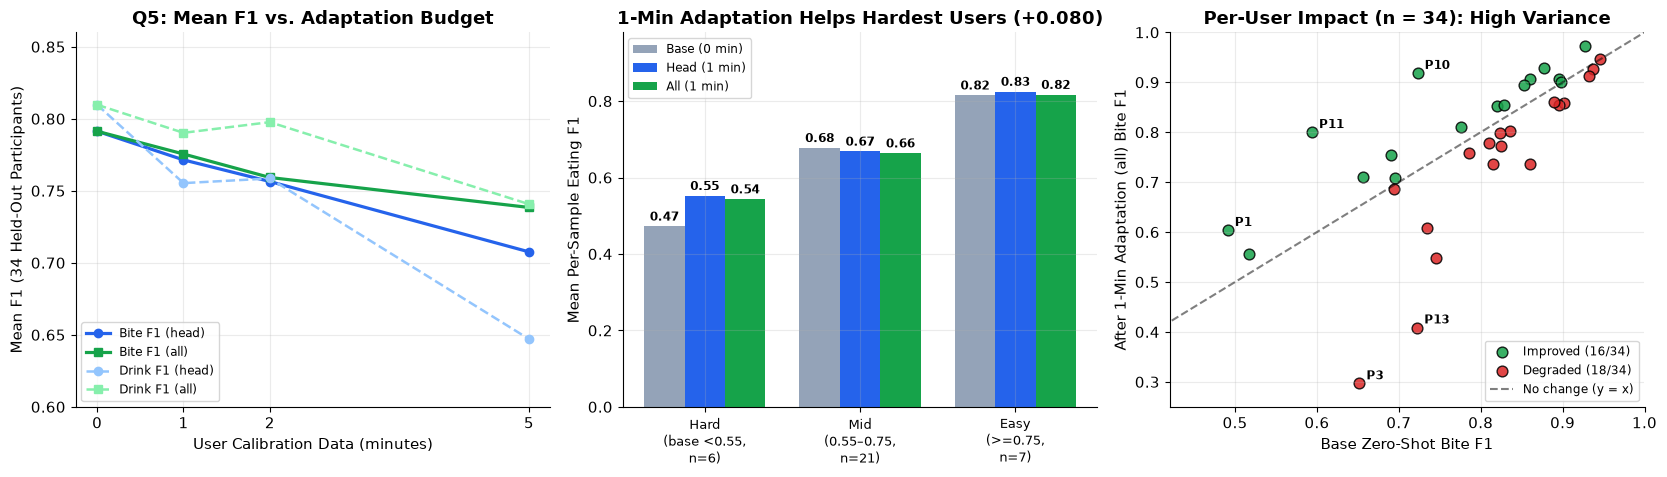

In [12]:
q5 = load_json(RUNS_DIR / "fd1_personalization_cnn_7fold" / "personalization.json")
pts = q5["per_participant"]
variants = ["base", "head_1min", "all_1min", "head_2min", "all_2min", "head_5min", "all_5min"]

try:
    from scipy.stats import wilcoxon
    def paired_p(a, b):
        diff = a - b
        return float(wilcoxon(diff).pvalue) if np.any(diff != 0) else 1.0
    test_name = "Wilcoxon p"
except ImportError:
    def paired_p(a, b):
        diff = a - b
        rng = np.random.default_rng(42)
        obs = abs(diff.mean())
        signs = rng.choice([-1, 1], size=(10000, len(diff)))
        return float((np.abs((signs * diff).mean(axis=1)) >= obs).mean())
    test_name = "Perm p"

base_eat = np.array([p["base"]["eating_f1"] for p in pts])
base_bite = np.array([p["base"]["bite_f1"] for p in pts])

# 1. Print full statistical summary table across all 34 participants
print(f"Q5 7-FOLD PERSONALIZATION SUMMARY (n = {len(pts)} held-out participants)")
print(f"{'variant':<11} {'eat F1 (mean±SD)':>17} {'drk F1':>8} {'bite F1 (mean±SD)':>18} {'med':>6} {'wins':>7} {test_name:>11} {'MAE (med)':>12}")
print("-" * 98)
for v in variants:
    ef = np.array([p[v]["eating_f1"] for p in pts])
    df = np.array([p[v]["drinking_f1"] for p in pts])
    bf = np.array([p[v]["bite_f1"] for p in pts])
    err = np.array([p[v]["bite_count_error"] for p in pts])
    wins = f"{int((bf > base_bite).sum())}/{len(pts)}" if v != "base" else "-"
    pval = f"{paired_p(bf, base_bite):.4f}" if v != "base" else "-"
    print(f"{v:<11} {ef.mean():.3f} ± {ef.std():.3f}    {df.mean():>7.3f}  {bf.mean():.3f} ± {bf.std():.3f}   "
          f"{np.median(bf):>6.3f} {wins:>7} {pval:>11} {err.mean():>5.1f} ({np.median(err):.1f})")

# 2. Print stratified Hard vs Mid vs Easy breakdown (by base Eat F1)
print("\nSTRATIFIED BY BASE EATING F1 (Hard vs. Easy Unseen Users)")
for label, lo, hi in [("Hard (<0.55)", -1, 0.55), ("Mid (0.55-0.75)", 0.55, 0.75), ("Easy (>=0.75)", 0.75, 2.0)]:
    grp = [p for p in pts if lo <= p["base"]["eating_f1"] < hi]
    b_m = np.mean([p["base"]["eating_f1"] for p in grp])
    h1_m = np.mean([p["head_1min"]["eating_f1"] for p in grp])
    a1_m = np.mean([p["all_1min"]["eating_f1"] for p in grp])
    print(f"  {label:<16} (n={len(grp):2d}): base {b_m:.3f} -> head_1min {h1_m:.3f} ({h1_m - b_m:+.3f}) | all_1min {a1_m:.3f} ({a1_m - b_m:+.3f})")

# 3. 3-Panel Poster Figure (300 DPI)
fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.9))

# Panel A: Budget curves (0, 1, 2, 5 min) for Bite F1 & Drink F1
budgets = [0, 1, 2, 5]
head_bite = [q5["averages"][k]["bite_f1"] for k in ("base", "head_1min", "head_2min", "head_5min")]
all_bite = [q5["averages"][k]["bite_f1"] for k in ("base", "all_1min", "all_2min", "all_5min")]
head_drk = [q5["averages"][k]["drinking_f1"] for k in ("base", "head_1min", "head_2min", "head_5min")]
all_drk = [q5["averages"][k]["drinking_f1"] for k in ("base", "all_1min", "all_2min", "all_5min")]

axes[0].plot(budgets, head_bite, marker="o", linewidth=2.3, color="#2563eb", label="Bite F1 (head)")
axes[0].plot(budgets, all_bite, marker="s", linewidth=2.3, color="#16a34a", label="Bite F1 (all)")
axes[0].plot(budgets, head_drk, marker="o", linewidth=1.8, linestyle="--", color="#93c5fd", label="Drink F1 (head)")
axes[0].plot(budgets, all_drk, marker="s", linewidth=1.8, linestyle="--", color="#86efac", label="Drink F1 (all)")
axes[0].set_xticks(budgets)
axes[0].set_ylim(0.60, 0.86)
axes[0].set_xlabel("User Calibration Data (minutes)")
axes[0].set_ylabel("Mean F1 (34 Held-Out Participants)")
axes[0].set_title("Q5: Mean F1 vs. Adaptation Budget")
axes[0].legend(fontsize=8.5, loc="lower left")

# Panel B: Hard vs Mid vs Easy Users (Base vs 1-min Adaptation on Eat F1)
groups = [
    ("Hard\n(base <0.55,\nn=6)", [p for p in pts if p["base"]["eating_f1"] < 0.55]),
    ("Mid\n(0.55–0.75,\nn=21)", [p for p in pts if 0.55 <= p["base"]["eating_f1"] < 0.75]),
    ("Easy\n(>=0.75,\nn=7)", [p for p in pts if p["base"]["eating_f1"] >= 0.75]),
]
x = np.arange(len(groups))
w = 0.26
b_vals = [np.mean([p["base"]["eating_f1"] for p in g]) for _, g in groups]
h1_vals = [np.mean([p["head_1min"]["eating_f1"] for p in g]) for _, g in groups]
a1_vals = [np.mean([p["all_1min"]["eating_f1"] for p in g]) for _, g in groups]

r1 = axes[1].bar(x - w, b_vals, w, label="Base (0 min)", color="#94a3b8")
r2 = axes[1].bar(x, h1_vals, w, label="Head (1 min)", color="#2563eb")
r3 = axes[1].bar(x + w, a1_vals, w, label="All (1 min)", color="#16a34a")
axes[1].set_xticks(x); axes[1].set_xticklabels([lbl for lbl, _ in groups], fontsize=9.5)
axes[1].set_ylim(0, 0.98)
axes[1].set_ylabel("Mean Per-Sample Eating F1")
axes[1].set_title("1-Min Adaptation Helps Hardest Users (+0.080)")
axes[1].legend(fontsize=8.5)
for bars in (r1, r2, r3):
    for bar in bars:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.2f}", ha="center", fontsize=8.5, fontweight="bold")

# Panel C: Per-participant scatter (Base vs 1-min All Bite F1)
a1_bite = np.array([p["all_1min"]["bite_f1"] for p in pts])
improved = a1_bite > base_bite
axes[2].scatter(base_bite[improved], a1_bite[improved], s=60, color="#16a34a", edgecolors="black", alpha=0.85,
                label=f"Improved ({improved.sum()}/34)")
axes[2].scatter(base_bite[~improved], a1_bite[~improved], s=60, color="#dc2626", edgecolors="black", alpha=0.85,
                label=f"Degraded ({(~improved).sum()}/34)")
axes[2].plot([0.25, 1.0], [0.25, 1.0], "k--", alpha=0.5, label="No change (y = x)")

# Annotate top 3 gainers and top 2 drops
deltas = sorted([(a1_bite[i] - base_bite[i], i) for i in range(len(pts))])
for idx in [deltas[0][1], deltas[1][1], deltas[-1][1], deltas[-2][1], deltas[-3][1]]:
    pid = pts[idx]["participant_id"]
    axes[2].annotate(f"P{pid}", (base_bite[idx], a1_bite[idx]), xytext=(5, 3), textcoords="offset points", fontsize=8.5, fontweight="bold")

axes[2].set_xlim(0.42, 1.0); axes[2].set_ylim(0.25, 1.0)
axes[2].set_xlabel("Base Zero-Shot Bite F1")
axes[2].set_ylabel("After 1-Min Adaptation (all) Bite F1")
axes[2].set_title("Per-User Impact (n = 34): High Variance")
axes[2].legend(fontsize=8.5, loc="lower right")

plt.tight_layout()
save_fig(fig, "07_fd1_q5_personalization.png")
plt.show()